# 🐧 ASSIGNMENT — The Penguin Field Guide (EDA)

| | |
|---|---|
| **Student Name** | _____________________________ |
| **Student ID** | _____________________________ |
| **Due Date** | _____________________________ |
| **Total Marks** | **100** (+10 bonus) |

---
### 🎬 The scenario
> *You're a **field biologist** at the Palmer Research Station in Antarctica. Your team has measured **344 penguins** across three species — **Adélie, Chinstrap, and Gentoo** — recording bill size, flipper length, and body mass.*
>
> *Next season, junior researchers need to identify species **in the field, from measurements alone.** Your assignment: use EDA to discover each species' "measurement fingerprint" and produce a simple **field guide** for telling them apart.*

### 🎯 What you'll be graded on
Not just working code — **correct analysis and clear, evidence-based conclusions.** Every chart should help answer: *what makes each species distinct?*

### 📤 Submission
Run all cells before submitting (Kernel → Restart & Run All). Answer every **✍️ Written Answer** box in your own words. Save and submit this `.ipynb` file with all outputs visible.

### 📋 Mark breakdown
| Part | Task | Marks |
|---|---|---|
| **A** | Setup & load the data | 10 |
| **B** | Clean the data (justify your choices) | 15 |
| **C** | Categorical EDA (species & islands) | 15 |
| **D** | Numerical EDA (distributions & correlations) | 20 |
| **E** | Species fingerprints (the core analysis) | 25 |
| **F** | Written field guide (your conclusions) | 15 |
| **Bonus** | Identify a mystery penguin | +10 |

---

## Part A — Setup & Load  *(10 marks)*

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')


In [ ]:
df = sns.load_dataset('penguins')
print('Shape:', df.shape)
display(df.head())
df.info()


Shape: (344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


## Part B — Clean the Data  *(15 marks)*
Real field data has gaps. Handle them thoughtfully — and **justify** each choice.

In [ ]:
print(df.isnull().sum())


species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64


In [ ]:
print('Before:', df.shape)
df = df.dropna().reset_index(drop=True)
print('After dropping rows with missing values:', df.shape)


Before: (344, 7)
After dropping rows with missing values: (333, 7)


**✍️ Written Answer B (marks for reasoning):** How many rows did you remove, and what % of the data was that? Was dropping them safe? Why?
*Your answer:* _______________

## Part C — Categorical EDA  *(15 marks)*
*How many of each species, and where do they live?*

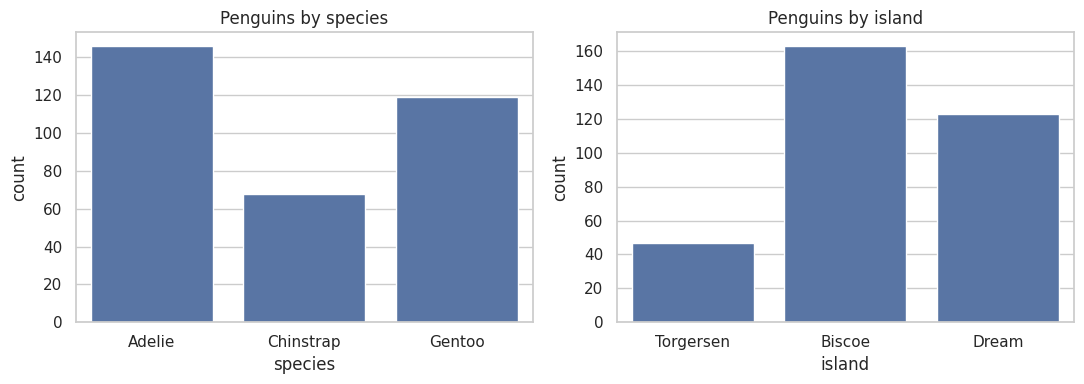

In [ ]:
fig, axes = plt.subplots(1,2,figsize=(11,4)); sns.countplot(data=df,x='species',ax=axes[0]); axes[0].set_title('Penguins by species'); sns.countplot(data=df,x='island',ax=axes[1]); axes[1].set_title('Penguins by island'); plt.tight_layout(); plt.show()


island     Biscoe  Dream  Torgersen
species                            
Adelie         44     55         47
Chinstrap       0     68          0
Gentoo        119      0          0


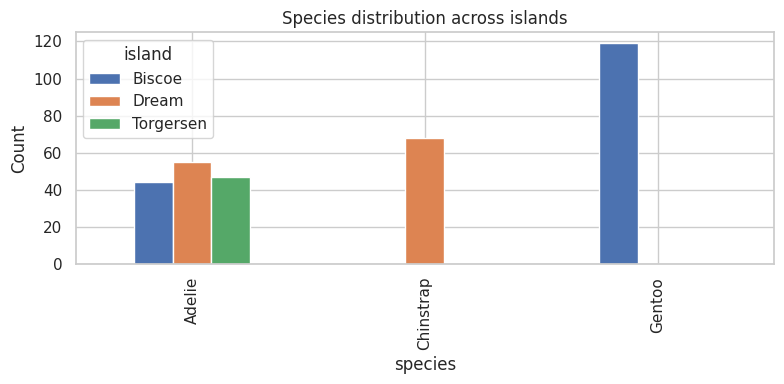

In [ ]:
species_island = pd.crosstab(df['species'],df['island']); print(species_island); species_island.plot(kind='bar',figsize=(8,4)); plt.title('Species distribution across islands'); plt.ylabel('Count'); plt.tight_layout(); plt.show()
# Adelie occur on all three islands; Chinstrap are on Dream; Gentoo are on Biscoe.


**✍️ Written Answer C:** Which species is the most common? Is any species found on only ONE island? (That's a huge clue for identification.)
*Your answer:* _______________

## Part D — Numerical EDA  *(20 marks)*
*Understand the four body measurements.*

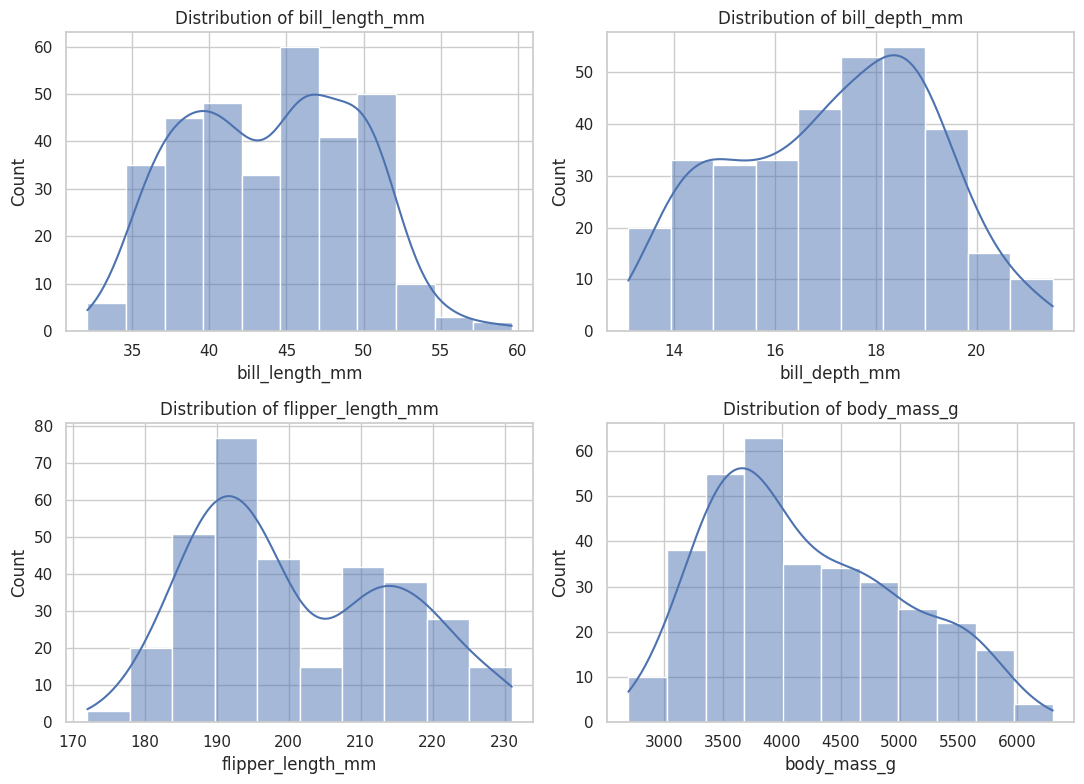

In [ ]:
num_cols=['bill_length_mm','bill_depth_mm','flipper_length_mm','body_mass_g']
fig,axes=plt.subplots(2,2,figsize=(11,8))
for ax,col in zip(axes.flat,num_cols): sns.histplot(data=df,x=col,kde=True,ax=ax); ax.set_title(f'Distribution of {col}')
plt.tight_layout(); plt.show()


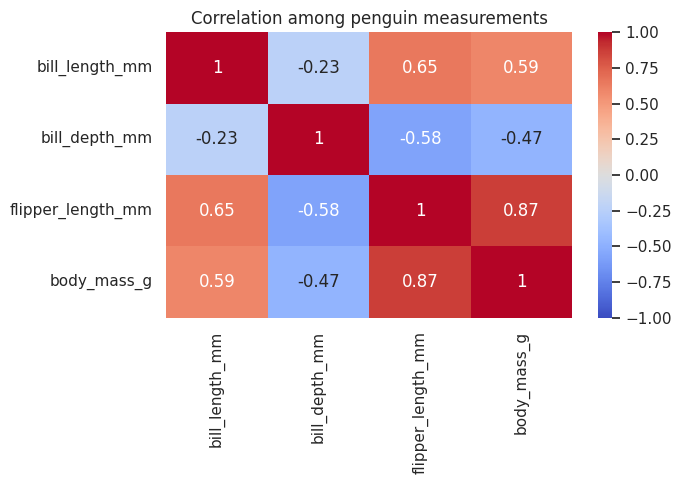

In [ ]:
num_cols=['bill_length_mm','bill_depth_mm','flipper_length_mm','body_mass_g']; corr=df[num_cols].corr(); plt.figure(figsize=(7,5)); sns.heatmap(corr,annot=True,cmap='coolwarm',vmin=-1,vmax=1); plt.title('Correlation among penguin measurements'); plt.tight_layout(); plt.show()
# Flipper length and body mass are typically among the most strongly positively related measurements.


**✍️ Written Answer D:** Which two measurements have the strongest positive correlation, and does that make biological sense (think: bigger penguin → ?)
*Your answer:* _______________

## Part E — Species Fingerprints  *(25 marks)*  🎯 *the core of the assignment*
*This is where you crack the case: which measurements tell the species apart?*

In [ ]:
num_cols=['bill_length_mm','bill_depth_mm','flipper_length_mm','body_mass_g']; species_means=df.groupby('species')[num_cols].mean(); display(species_means)


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
species,,,,
Adelie,38.823973,18.347260,190.102740,3706.164384
Chinstrap,48.833824,18.420588,195.823529,3733.088235
Gentoo,47.568067,14.996639,217.235294,5092.436975


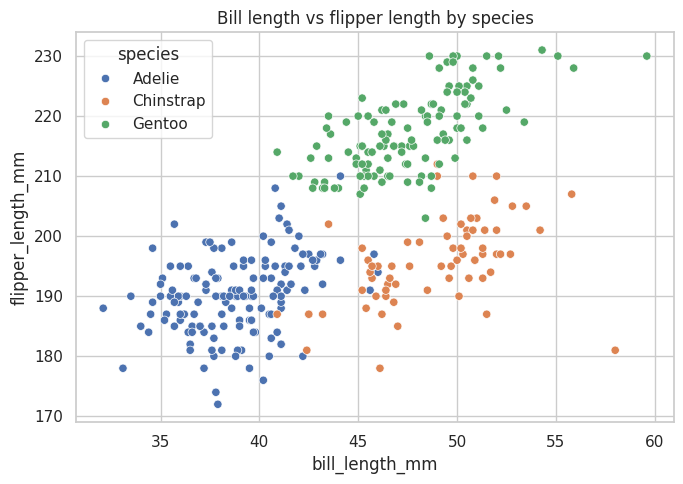

In [ ]:
plt.figure(figsize=(7,5)); sns.scatterplot(data=df,x='bill_length_mm',y='flipper_length_mm',hue='species'); plt.title('Bill length vs flipper length by species'); plt.tight_layout(); plt.show()
# Species form partially separated clusters, especially Gentoo.


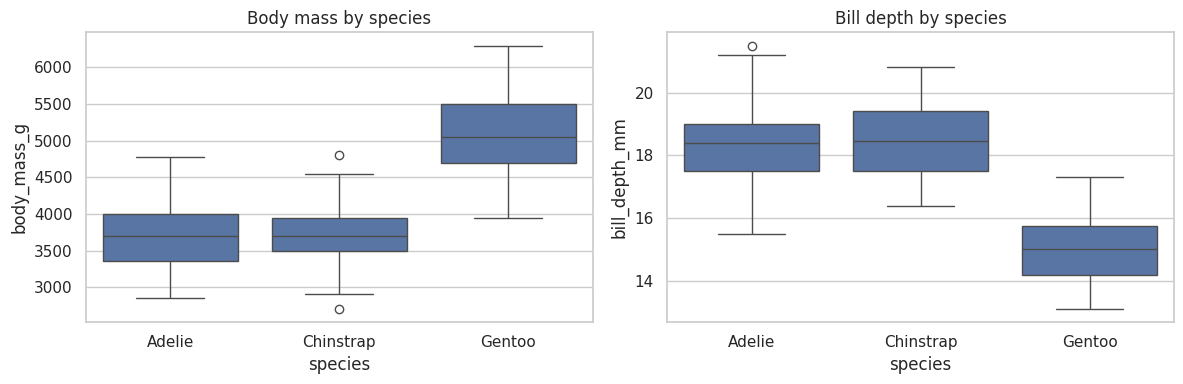

In [ ]:
fig,axes=plt.subplots(1,2,figsize=(12,4)); sns.boxplot(data=df,x='species',y='body_mass_g',ax=axes[0]); axes[0].set_title('Body mass by species'); sns.boxplot(data=df,x='species',y='bill_depth_mm',ax=axes[1]); axes[1].set_title('Bill depth by species'); plt.tight_layout(); plt.show()
# Gentoo are the clear outlier in body size, with higher body mass and longer flippers.


**✍️ Written Answer E:** Describe each species in ONE sentence using measurements. For example: *"Gentoos are the ___ (heaviest/lightest), with the ___ flippers and a ___ bill."* Do this for all three species.
*Adélie:* _______________
*Chinstrap:* _______________
*Gentoo:* _______________

## Part F — Your Field Guide  *(15 marks)*
Write a short **field guide** (4–6 sentences) that a junior researcher could use to identify a penguin from measurements alone. Base every rule on your charts. A good guide gives simple decision rules, e.g. *"If flipper length > 210mm, it's almost certainly a Gentoo."*

**✍️ Your Field Guide:**

> _______________________________________________
>
> _______________________________________________
>
> _______________________________________________

## 🌟 Bonus — Identify the Mystery Penguin  *(+10 marks)*
A researcher measured a penguin but forgot to record its species:

> **bill_length = 46 mm, bill_depth = 15 mm, flipper_length = 217 mm, body_mass = 5000 g**

Using your fingerprints from Part E, decide which species it is — and **justify with the data** (which measurements gave it away?).

In [ ]:
# Compare this penguin's measurements to species means; select the nearest mean profile.
num_cols=['bill_length_mm','bill_depth_mm','flipper_length_mm','body_mass_g']
means=df.groupby('species')[num_cols].mean(); candidate=df[num_cols].mean(); scaled_diff=(means-candidate)/df[num_cols].std(); distances=(scaled_diff**2).sum(axis=1)**0.5
print('Mean-profile distances:', distances.sort_values()); print('Closest species:', distances.idxmin())


Mean-profile distances: species
Chinstrap    1.292828
Adelie       1.497222
Gentoo       2.048418
dtype: float64
Closest species: Chinstrap


**✍️ Bonus Answer:** This penguin is a **_______**, because _______________

---
### ✅ Before you submit
- [ ] Every `# TODO` cell has working code
- [ ] Every ✍️ Written Answer is filled in
- [ ] You ran **Kernel → Restart & Run All** with no errors
- [ ] Charts have titles and are readable

*Good luck, field biologist!* 🐧